# Exploración de datos Sentinel-2 y estructura de los CSV

**Proyecto:** Sistema Inteligente de Recomendación de Riego para el Cultivo de Patata
**Trabajo de Fin de Grado · Sprint 2 · Issue #2**

## Contenido

- **Parte 1.** Estructura de los CSV de las cuatro parcelas (extracción
  provisional del 2026-04-01, incluido, al 2026-10-01, excluido), generados por
  el notebook `03_extraccion_sentinel2_parcelas_reales`.
- **Parte 2.** Exploración previa con un CSV de **maíz de 2018**. Es un ejemplo
  metodológico: no contiene datos de las parcelas reales ni de patata.

## Límites que se mantienen en todo el notebook

- El periodo de extracción es provisional y no se confirma el cultivo presente
  en cada parcela durante ese periodo.
- Los índices Sentinel-2 describen la vegetación; no miden la humedad del suelo.
- La Parte 1 no interpola, no rellena huecos y no emite recomendaciones de riego.
- Las semanas sin observaciones seleccionadas conservan valores ausentes.

# Parte 1 - CSV de las cuatro parcelas (2026, periodo provisional)

## 1.1 Configuración y acceso a Drive

Si el notebook se ejecuta fuera de Colab, se omite el montaje de Drive y hay que
ajustar `BASE` a una ruta local.

In [48]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Fuera de Colab: no se monta Drive. Ajusta BASE a una ruta local.")

BASE = Path("/content/drive/MyDrive/TFG_PATATAS_TRABAJO")
PERIODO = ("2026-04-01", "2026-10-01")
PARCELAS_ESPERADAS = ["pancostales", "puri", "la_culebra", "los_ceres"]
RESULTADOS = BASE / "resultados" / "analisis_estructura_csv"

print("Carpeta base:", BASE, "| existe:", BASE.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta base: /content/drive/MyDrive/TFG_PATATAS_TRABAJO | existe: True


In [49]:
import datetime as dt

carpeta_lotes = BASE / "resultados" / "sentinel2_lotes"
print("¿Existe la carpeta de lotes?", carpeta_lotes.exists())

for ruta in sorted(carpeta_lotes.rglob("*.csv")):
    info = ruta.stat()
    print(f"{ruta.relative_to(carpeta_lotes).as_posix():<110} "
          f"{info.st_size/1024:8.1f} KB  {dt.datetime.fromtimestamp(info.st_mtime):%Y-%m-%d %H:%M}")

¿Existe la carpeta de lotes? True
provisional/comparativas/2026-04-01_2026-10-01/comparativa_parcelas.csv                                             0.7 KB  2026-10-16 00:04
provisional/comparativas/2026-04-01_2026-10-01/revision_fechas_seleccionadas.csv                                    0.1 KB  2026-10-16 00:04
provisional/la_culebra/2026-04-01_2026-10-01/la_culebra_sentinel2_indices_2026-04-01_2026-10-01.csv                33.9 KB  2026-10-16 00:04
provisional/la_culebra/2026-04-01_2026-10-01/la_culebra_sentinel2_indices_calidad_2026-04-01_2026-10-01.csv        43.0 KB  2026-10-16 00:04
provisional/la_culebra/2026-04-01_2026-10-01/la_culebra_sentinel2_semanal_2026-04-01_2026-10-01.csv                 6.8 KB  2026-10-16 00:04
provisional/la_culebra/2026-04-01_2026-10-01/resumen_ejecucion.csv                                                  0.4 KB  2026-10-16 00:04
provisional/la_culebra/2026-04-01_2026-10-01/revision_calidad_imagenes.csv                                          3.7 

## 1.2 Localizar los CSV de cada parcela

Se buscan tres tipos de archivo generados por el notebook 03 para el periodo
indicado: el CSV de índices (uno por imagen con píxeles válidos), el CSV de
revisión de calidad y el resumen semanal. Si falta alguna parcela o hay archivos
duplicados, el notebook se detiene para no mezclar ejecuciones distintas.

In [50]:
sufijo_periodo = f"{PERIODO[0]}_{PERIODO[1]}"
carpeta_lotes = BASE / "resultados" / "sentinel2_lotes"

def buscar(patron, excluir=()):
    encontrados = {p: [] for p in PARCELAS_ESPERADAS}
    for ruta in sorted(carpeta_lotes.rglob(patron)):
        if sufijo_periodo not in ruta.name or any(t in ruta.name for t in excluir):
            continue
        for p in PARCELAS_ESPERADAS:
            if ruta.name.startswith(f"{p}_sentinel2_"):
                encontrados[p].append(ruta)
    return encontrados

hallados = {
    "indices": buscar("*_sentinel2_indices_*.csv", excluir=("calidad",)),
    "calidad": buscar("*_sentinel2_indices_calidad_*.csv"),
    "semanal": buscar("*_sentinel2_semanal_*.csv"),
}

for tipo, por_parcela in hallados.items():
    faltan = [p for p, rutas in por_parcela.items() if not rutas]
    repetidos = {p: [r.name for r in rutas] for p, rutas in por_parcela.items() if len(rutas) > 1}
    if faltan:
        raise FileNotFoundError(f"Faltan CSV de tipo '{tipo}' para: {faltan}. Revisa BASE y los nombres.")
    if repetidos:
        raise ValueError(f"Hay varios archivos de tipo '{tipo}' para una parcela: {repetidos}")

csv_indices = {p: hallados["indices"][p][0] for p in PARCELAS_ESPERADAS}
csv_calidad = {p: hallados["calidad"][p][0] for p in PARCELAS_ESPERADAS}
csv_semanal = {p: hallados["semanal"][p][0] for p in PARCELAS_ESPERADAS}

tabla_archivos = pd.DataFrame({
    "parcela": PARCELAS_ESPERADAS,
    "csv_indices": [csv_indices[p].relative_to(BASE).as_posix() for p in PARCELAS_ESPERADAS],
})
display(tabla_archivos)

,parcela,csv_indices
0,pancostales,resultados/sentinel2_lotes/provisional/pancost...
1,puri,resultados/sentinel2_lotes/provisional/puri/20...
2,la_culebra,resultados/sentinel2_lotes/provisional/la_cule...
3,los_ceres,resultados/sentinel2_lotes/provisional/los_cer...


## 1.3 Carga y resumen por parcela

Se distingue entre **filas** (una por imagen con píxeles válidos), **imágenes
distintas** y **fechas distintas**. Una parcela situada en dos teselas puede
tener varias imágenes en la misma fecha.

In [51]:
def columna_imagen(df):
    return next((c for c in df.columns if c.lower().replace("_", "") == "imageid"), None)

dfs = {
    p: pd.read_csv(ruta, parse_dates=["date"], encoding="utf-8-sig")
    for p, ruta in csv_indices.items()
}

filas = []
for p, df_p in dfs.items():
    col_img = columna_imagen(df_p)
    por_fecha = df_p["date"].value_counts()
    filas.append({
        "parcela": p,
        "filas": len(df_p),
        "columnas": df_p.shape[1],
        "imagenes_distintas": df_p[col_img].nunique() if col_img else None,
        "fechas_distintas": df_p["date"].nunique(),
        "fechas_con_varias_filas": int((por_fecha > 1).sum()),
        "primera_fecha": df_p["date"].min().strftime("%Y-%m-%d"),
        "ultima_fecha": df_p["date"].max().strftime("%Y-%m-%d"),
        "celdas_nulas": int(df_p.isna().sum().sum()),
    })

resumen = pd.DataFrame(filas)
display(resumen)

,parcela,filas,columnas,imagenes_distintas,fechas_distintas,fechas_con_varias_filas,primera_fecha,ultima_fecha,celdas_nulas
0,pancostales,39,56,39,39,0,2026-04-10,2026-09-24,0
1,puri,68,56,68,35,33,2026-04-10,2026-09-24,0
2,la_culebra,39,56,39,39,0,2026-04-10,2026-09-24,0
3,los_ceres,35,56,35,35,0,2026-04-10,2026-09-24,0


## 1.4 Columnas: comparación entre parcelas

Las cuatro parcelas deben compartir exactamente las mismas columnas y en el mismo
orden. Cualquier diferencia se muestra en las columnas `faltan` y `sobran`.

In [52]:
parcela_ref = PARCELAS_ESPERADAS[0]
columnas_ref = list(dfs[parcela_ref].columns)

comparacion_columnas = pd.DataFrame([
    {
        "parcela": p,
        "mismas_columnas_y_orden": list(df_p.columns) == columnas_ref,
        "faltan": sorted(set(columnas_ref) - set(df_p.columns)),
        "sobran": sorted(set(df_p.columns) - set(columnas_ref)),
    }
    for p, df_p in dfs.items()
])
display(comparacion_columnas)

print(f"Columnas de la parcela de referencia ({parcela_ref}): {len(columnas_ref)}")
for numero, columna in enumerate(columnas_ref, start=1):
    print(f"{numero:02d}. {columna}")

,parcela,mismas_columnas_y_orden,faltan,sobran
0,pancostales,True,[],[]
1,puri,True,[],[]
2,la_culebra,True,[],[]
3,los_ceres,True,[],[]


Columnas de la parcela de referencia (pancostales): 56
01. parcela_id
02. nombre_parcela
03. municipio
04. variedad_catalogo
05. date
06. image_id
07. cloud_percentage
08. periodo_provisional
09. cultivo_confirmado_en_periodo
10. fecha_inicio_incluida
11. fecha_fin_excluida
12. escala_estadisticas_m
13. umbral_probabilidad_nube
14. NDVI_mean
15. NDVI_stdDev
16. NDVI_min
17. NDVI_max
18. NDVI_median
19. NDVI_p25
20. NDVI_p75
21. NDVI_count
22. NDMI_mean
23. NDMI_stdDev
24. NDMI_min
25. NDMI_max
26. NDMI_median
27. NDMI_p25
28. NDMI_p75
29. NDMI_count
30. MSI_mean
31. MSI_stdDev
32. MSI_min
33. MSI_max
34. MSI_median
35. MSI_p25
36. MSI_p75
37. MSI_count
38. EVI_mean
39. EVI_stdDev
40. EVI_min
41. EVI_max
42. EVI_median
43. EVI_p25
44. EVI_p75
45. EVI_count
46. SAVI_mean
47. SAVI_stdDev
48. SAVI_min
49. SAVI_max
50. SAVI_median
51. SAVI_p25
52. SAVI_p75
53. SAVI_count
54. pixeles_antes
55. pixeles_despues
56. porcentaje_conservado


## 1.5 Agrupación de columnas y tipos de datos

Las estadísticas siguen el patrón `ÍNDICE_estadístico` (por ejemplo `NDVI_mean`).
Revisa la columna `grupo`: lo que aparezca como `otras` no está clasificado y
conviene explicarlo en el documento de análisis.

In [53]:
SUFIJOS = ["mean", "stdDev", "std", "min", "max", "median", "p25", "p75", "count"]
indices = sorted({c[: -len("_mean")] for c in columnas_ref if c.endswith("_mean")})

def grupo_columna(columna):
    for indice in indices:
        if columna.startswith(indice + "_") and columna[len(indice) + 1:] in SUFIJOS:
            return f"estadistica_{columna[len(indice) + 1:]}"
    k = columna.lower()
    if k == "date" or k.endswith("id") or any(t in k for t in ("nombre", "municipio", "variedad")):
        return "identificacion"
    if any(t in k for t in ("cloud", "pixel", "conservado", "cobertura")):
        return "calidad"
    if any(t in k for t in ("periodo", "cultivo", "fecha_", "escala", "umbral")):
        return "contexto_extraccion"
    return "otras"

estructura = pd.DataFrame({
    "columna": columnas_ref,
    "grupo": [grupo_columna(c) for c in columnas_ref],
    "tipo": dfs[parcela_ref].dtypes.astype(str).values,
    "nulos_en_referencia": dfs[parcela_ref].isna().sum().values,
})

print("Índices detectados:", indices)
display(estructura.groupby("grupo").size().rename("n_columnas").to_frame())
display(estructura)

tipos_por_parcela = pd.DataFrame({p: df_p.dtypes.astype(str) for p, df_p in dfs.items()})
diferencias_tipos = tipos_por_parcela[tipos_por_parcela.nunique(axis=1) > 1]
if diferencias_tipos.empty:
    print("Los tipos de datos coinciden en las cuatro parcelas.")
else:
    display(diferencias_tipos)

Índices detectados: ['EVI', 'MSI', 'NDMI', 'NDVI', 'SAVI']


,n_columnas
grupo,
calidad,4
contexto_extraccion,6
estadistica_count,5
estadistica_max,5
estadistica_mean,5
estadistica_median,5
estadistica_min,5
estadistica_p25,5
estadistica_p75,5


,columna,grupo,tipo,nulos_en_referencia
0,parcela_id,identificacion,object,0
1,nombre_parcela,identificacion,object,0
2,municipio,identificacion,object,0
3,variedad_catalogo,identificacion,object,0
4,date,identificacion,datetime64[ns],0
5,image_id,identificacion,object,0
6,cloud_percentage,calidad,float64,0
7,periodo_provisional,contexto_extraccion,bool,0
8,cultivo_confirmado_en_periodo,contexto_extraccion,bool,0
9,fecha_inicio_incluida,contexto_extraccion,object,0


Los tipos de datos coinciden en las cuatro parcelas.


## 1.6 Valores ausentes

Se cuentan los valores nulos por columna y parcela. En el CSV de índices cada fila
procede de una imagen con píxeles válidos, de modo que se esperan pocos nulos. Los
huecos temporales no aparecen aquí: se estudian en el apartado siguiente.

In [54]:
nulos_por_columna = pd.DataFrame({p: df_p.isna().sum() for p, df_p in dfs.items()})
nulos_con_valores = nulos_por_columna[nulos_por_columna.sum(axis=1) > 0]

if nulos_con_valores.empty:
    print("No hay valores nulos en ninguna columna de las cuatro parcelas.")
else:
    display(nulos_con_valores)

No hay valores nulos en ninguna columna de las cuatro parcelas.


## 1.7 Fechas, huecos e imágenes repetidas

Se calculan los intervalos entre fechas distintas y se listan los huecos de 15 días
o más. También se comprueba qué fechas tienen más de una fila.

In [55]:
UMBRAL_HUECO_DIAS = 15

filas_fechas, huecos = [], []
for p, df_p in dfs.items():
    fechas = df_p["date"].drop_duplicates().sort_values().reset_index(drop=True)
    intervalos = fechas.diff().dt.days.dropna()
    filas_fechas.append({
        "parcela": p,
        "fechas_distintas": len(fechas),
        "intervalo_minimo_dias": intervalos.min(),
        "intervalo_mediano_dias": intervalos.median(),
        "intervalo_medio_dias": round(intervalos.mean(), 2),
        "intervalo_maximo_dias": intervalos.max(),
    })
    for posicion in intervalos[intervalos >= UMBRAL_HUECO_DIAS].index:
        huecos.append({
            "parcela": p,
            "desde": fechas[posicion - 1].strftime("%Y-%m-%d"),
            "hasta": fechas[posicion].strftime("%Y-%m-%d"),
            "dias": int(intervalos[posicion]),
        })

resumen_fechas = pd.DataFrame(filas_fechas)
huecos_largos = pd.DataFrame(huecos)
display(resumen_fechas)
print(f"Huecos de {UMBRAL_HUECO_DIAS} días o más entre fechas con imagen válida:")
display(huecos_largos if not huecos_largos.empty else "Ninguno")

repetidas = []
for p, df_p in dfs.items():
    col_img = columna_imagen(df_p)
    conteo = df_p.groupby("date").size()
    for fecha, n in conteo[conteo > 1].items():
        repetidas.append({
            "parcela": p,
            "fecha": fecha.strftime("%Y-%m-%d"),
            "filas": int(n),
            "imagenes": sorted(df_p.loc[df_p["date"] == fecha, col_img].astype(str)) if col_img else None,
        })
fechas_repetidas = pd.DataFrame(repetidas)
print("Fechas con más de una fila en el CSV de índices:")
display(fechas_repetidas.head(10) if not fechas_repetidas.empty else "Ninguna")
if not fechas_repetidas.empty:
    print("Total de fechas repetidas por parcela:")
    display(fechas_repetidas.groupby("parcela").size().rename("fechas_repetidas").to_frame())

,parcela,fechas_distintas,intervalo_minimo_dias,intervalo_mediano_dias,intervalo_medio_dias,intervalo_maximo_dias
0,pancostales,39,2.0,4.0,4.39,12.0
1,puri,35,2.0,5.0,4.91,13.0
2,la_culebra,39,2.0,3.0,4.39,10.0
3,los_ceres,35,2.0,5.0,4.91,10.0


Huecos de 15 días o más entre fechas con imagen válida:


'Ninguno'

Fechas con más de una fila en el CSV de índices:


,parcela,fecha,filas,imagenes
0,puri,2026-04-10,2,"[20260410T110619_20260410T111231_T30TTL, 20260..."
1,puri,2026-04-15,2,"[20260415T110621_20260415T111656_T30TTL, 20260..."
2,puri,2026-04-17,2,"[20260417T110711_20260417T111030_T30TTL, 20260..."
3,puri,2026-04-27,2,"[20260427T110651_20260427T111921_T30TTL, 20260..."
4,puri,2026-05-10,2,"[20260510T110619_20260510T110713_T30TTL, 20260..."
5,puri,2026-05-15,2,"[20260515T110621_20260515T110821_T30TTL, 20260..."
6,puri,2026-05-20,2,"[20260520T110619_20260520T111859_T30TTL, 20260..."
7,puri,2026-05-30,2,"[20260530T110619_20260530T111655_T30TTL, 20260..."
8,puri,2026-06-06,2,"[20260606T110651_20260606T111917_T30TTL, 20260..."
9,puri,2026-06-09,2,"[20260609T110619_20260609T111722_T30TTL, 20260..."


Total de fechas repetidas por parcela:


,fechas_repetidas
parcela,
puri,33


## 1.8 Indicadores de calidad y cobertura

El CSV de índices conserva todas las imágenes con algún píxel válido, no solo las
buenas. Para decidir cuáles se usan, el notebook 03 aplica una **cobertura mínima
del 70 % por índice** y exige medias completas (`seleccion_tecnica_provisional`).
Ese criterio es distinto del filtro orientativo de la Parte 2 (50 % del máximo de
`NDVI_count`) y no deben mezclarse.

In [43]:
cols_calidad = ["cloud_percentage", "pixeles_antes", "pixeles_despues", "porcentaje_conservado"]
cols_count = [c for c in columnas_ref if c.endswith("_count")]

descripcion_calidad = pd.concat(
    {
        p: df_p[[c for c in cols_calidad if c in df_p.columns]].describe().T
        for p, df_p in dfs.items()
    },
    names=["parcela", "variable"],
)
display(descripcion_calidad.round(2))
print("Columnas de recuento de píxeles por índice:", cols_count)

def columna_que_contiene(df, *claves):
    return next(
        (c for c in df.columns if all(k in c.lower().replace("_", "") for k in claves)),
        None,
    )

dfs_calidad = {p: pd.read_csv(r, parse_dates=["date"], encoding="utf-8-sig") for p, r in csv_calidad.items()}

filas_sel = []
for p, dfq in dfs_calidad.items():
    col_sel = columna_que_contiene(dfq, "seleccion")
    col_cob = columna_que_contiene(dfq, "coberturaminima")
    seleccionadas = int(dfq[col_sel].astype(bool).sum()) if col_sel else None
    filas_sel.append({
        "parcela": p,
        "observaciones_revisadas": len(dfq),
        "seleccionadas": seleccionadas,
        "no_seleccionadas": len(dfq) - seleccionadas if seleccionadas is not None else None,
        "cobertura_minima_p50": round(dfq[col_cob].median(), 2) if col_cob else None,
    })
seleccion_provisional = pd.DataFrame(filas_sel)
display(seleccion_provisional)

count    mean    std     min     25%  \
parcela     variable                                                      
pancostales cloud_percentage        39.0   13.94  17.82    0.00    0.62   
            pixeles_antes           39.0  213.00   0.00  213.00  213.00   
            pixeles_despues         39.0  154.08  66.94   17.00  118.00   
            porcentaje_conservado   39.0   72.34  31.43    7.98   55.40   
puri        cloud_percentage        68.0   14.76  21.78    0.00    0.12   
            pixeles_antes           68.0   88.00  29.22   59.00   59.00   
            pixeles_despues         68.0   72.34  38.27    1.00   44.50   
            porcentaje_conservado   68.0   79.55  29.86    1.69   59.92   
la_culebra  cloud_percentage        39.0   15.59  19.49    0.00    1.14   
            pixeles_antes           39.0  303.00   0.00  303.00  303.00   
            pixeles_despues         39.0  225.23  94.11    9.00  194.50   
            porcentaje_conservado   39.0   74.33  31.06    2.97   64.19   
los_ceres   cloud_percentage        35.0   14.61  20.11    0.00    0.46   
            pixeles_antes           35.0  141.00   0.00  141.00  141.00   
            pixeles_despues         35.0  113.49  42.46   15.00  100.50   
            porcentaje_conservado   35.0   80.49  30.12   10.64   71.28   

                                      50%     75%     max  
parcela     variable                                       
pancostales cloud_percentage         4.62   21.91   64.60  
            pixeles_antes          213.00  213.00  213.00  
            pixeles_despues        184.00  213.00  213.00  
            porcentaje_conservado   86.38  100.00  100.00  
puri        cloud_percentage         3.25   22.19   86.01  
            pixeles_antes           88.00  117.00  117.00  
            pixeles_despues         59.00  116.25  117.00  
            porcentaje_conservado   99.57  100.00  100.00  
la_culebra  cloud_percentage         6.35   23.59   65.36  
            pixeles_antes          303.00  303.00  303.00  
            pixeles_despues        262.00  300.00  303.00  
            porcentaje_conservado   86.47   99.01  100.00  
los_ceres   cloud_percentage         3.76   23.33   65.36  
            pixeles_antes          141.00  141.00  141.00  
            pixeles_despues        136.00  141.00  141.00  
            porcentaje_conservado   96.45  100.00  100.00

Columnas de recuento de píxeles por índice: ['NDVI_count', 'NDMI_count', 'MSI_count', 'EVI_count', 'SAVI_count']


,parcela,observaciones_revisadas,seleccionadas,no_seleccionadas,cobertura_minima_p50
0,pancostales,39,25,14,86.77
1,puri,68,29,39,50.97
2,la_culebra,39,27,12,86.61
3,los_ceres,35,26,9,96.10


## 1.9 Resumen semanal sin interpolación

El CSV semanal agrupa de lunes (incluido) a lunes siguiente (excluido) y calcula la
media de las medias de las observaciones seleccionadas. Las semanas sin
observaciones conservan valores ausentes.

In [44]:
filas_sem = []
for p, ruta in csv_semanal.items():
    dsem = pd.read_csv(ruta, encoding="utf-8-sig")
    col_obs = columna_que_contiene(dsem, "tieneobservaciones")
    con_datos = int(dsem[col_obs].astype(bool).sum()) if col_obs else None
    filas_sem.append({
        "parcela": p,
        "semanas_totales": len(dsem),
        "semanas_con_observaciones": con_datos,
        "semanas_sin_observaciones": len(dsem) - con_datos if con_datos is not None else None,
    })
resumen_semanal = pd.DataFrame(filas_sem)
display(resumen_semanal)

,parcela,semanas_totales,semanas_con_observaciones,semanas_sin_observaciones
0,pancostales,27,17,10
1,puri,27,20,7
2,la_culebra,27,18,9
3,los_ceres,27,18,9


## 1.10 Contraste con la ejecución del notebook 03

Valores obtenidos en la ejecución del notebook 03 con el mismo periodo y los mismos
parámetros (umbral de nube 20, cobertura mínima 70 %, escala 20 m). Si alguno no
coincide, hay que registrar la discrepancia y su causa antes de documentar.

In [45]:
esperado = pd.DataFrame([
    {"parcela": "pancostales", "filas": 39, "fechas_distintas": 39, "seleccionadas": 25, "semanas_sin_observaciones": 10},
    {"parcela": "puri",        "filas": 68, "fechas_distintas": 35, "seleccionadas": 29, "semanas_sin_observaciones": 7},
    {"parcela": "la_culebra", "filas": 39, "fechas_distintas": 39, "seleccionadas": 27, "semanas_sin_observaciones": 9},
    {"parcela": "los_ceres",  "filas": 35, "fechas_distintas": 35, "seleccionadas": 26, "semanas_sin_observaciones": 9},
]).set_index("parcela")

obtenido = (
    resumen.set_index("parcela")[["filas", "fechas_distintas"]]
    .join(seleccion_provisional.set_index("parcela")[["seleccionadas"]])
    .join(resumen_semanal.set_index("parcela")[["semanas_sin_observaciones"]])
)

contraste = esperado.join(obtenido, lsuffix="_esperado", rsuffix="_obtenido")
for columna in esperado.columns:
    contraste[f"{columna}_coincide"] = contraste[f"{columna}_esperado"] == contraste[f"{columna}_obtenido"]
display(contraste)
print("Todas las comprobaciones coinciden:", bool(contraste.filter(like="_coincide").all().all()))

,filas_esperado,fechas_distintas_esperado,seleccionadas_esperado,semanas_sin_observaciones_esperado,filas_obtenido,fechas_distintas_obtenido,seleccionadas_obtenido,semanas_sin_observaciones_obtenido,filas_coincide,fechas_distintas_coincide,seleccionadas_coincide,semanas_sin_observaciones_coincide
parcela,,,,,,,,,,,,
pancostales,39,39,25,10,39,39,25,10,True,True,True,True
puri,68,35,29,7,68,35,29,7,True,True,True,True
la_culebra,39,39,27,9,39,39,27,9,True,True,True,True
los_ceres,35,35,26,9,35,35,26,9,True,True,True,True


Todas las comprobaciones coinciden: True


## 1.11 Índices disponibles y variables utilizables

Se comprueba qué índices solicitados en el plan existen realmente en la extracción
de 2026. En particular, **NDRE** no forma parte de este extractor: su tratamiento se
decide en la issue #3.

In [46]:
INDICES_PLAN = ["NDVI", "NDRE", "NDMI", "MSI", "EVI", "SAVI"]
disponibilidad = pd.DataFrame({
    "indice": INDICES_PLAN,
    "columna_media": [f"{i}_mean" for i in INDICES_PLAN],
    "disponible_en_2026": [f"{i}_mean" in columnas_ref for i in INDICES_PLAN],
})
display(disponibilidad)

ausentes = disponibilidad.loc[~disponibilidad["disponible_en_2026"], "indice"].tolist()
print("Índices del plan que NO están en la extracción de 2026:", ausentes or "ninguno")

,indice,columna_media,disponible_en_2026
0,NDVI,NDVI_mean,True
1,NDRE,NDRE_mean,False
2,NDMI,NDMI_mean,True
3,MSI,MSI_mean,True
4,EVI,EVI_mean,True
5,SAVI,SAVI_mean,True


Índices del plan que NO están en la extracción de 2026: ['NDRE']


| Elemento | ¿Lo aporta esta extracción? | Uso posterior |
|---|---|---|
| NDVI, NDMI, MSI, EVI, SAVI por imagen | Sí | Series por parcela; NDVI puede alimentar la estimación de Kc |
| Calidad y cobertura por imagen | Sí | Selección de observaciones |
| Resumen semanal sin interpolar | Sí | Entrada temporal para el simulador |
| NDRE | No | Pendiente de decisión en la issue #3 |
| Humedad del suelo, meteorología, riegos | No | Fuentes externas pendientes |
| Cultivo y fechas agronómicas confirmadas | No | Periodo provisional |

## 1.12 Guardar las tablas como evidencia

Se guardan las tablas de esta parte en Drive. Después, conserva las salidas del
notebook al subirlo a GitHub, pero **borra cualquier código de verificación o
token** que haya podido quedar en otras celdas.

In [47]:
RESULTADOS.mkdir(parents=True, exist_ok=True)

tablas = {
    "resumen_parcelas.csv": resumen,
    "comparacion_columnas.csv": comparacion_columnas,
    "estructura_columnas.csv": estructura,
    "resumen_fechas.csv": resumen_fechas,
    "huecos_largos.csv": huecos_largos,
    "fechas_repetidas.csv": fechas_repetidas,
    "seleccion_provisional.csv": seleccion_provisional,
    "resumen_semanal.csv": resumen_semanal,
    "contraste_notebook_03.csv": contraste.reset_index(),
    "disponibilidad_indices.csv": disponibilidad,
}

for nombre, tabla in tablas.items():
    tabla.to_csv(RESULTADOS / nombre, index=False, encoding="utf-8-sig")

print("Tablas guardadas en:", RESULTADOS)
for nombre in tablas:
    print(" -", nombre)

Tablas guardadas en: /content/drive/MyDrive/TFG_PATATAS_TRABAJO/resultados/analisis_estructura_csv
 - resumen_parcelas.csv
 - comparacion_columnas.csv
 - estructura_columnas.csv
 - resumen_fechas.csv
 - huecos_largos.csv
 - fechas_repetidas.csv
 - seleccion_provisional.csv
 - resumen_semanal.csv
 - contraste_notebook_03.csv
 - disponibilidad_indices.csv


# Parte 2 - Exploración previa con un CSV de maíz de 2018 (ejemplo metodológico)

Esta parte conserva la exploración inicial realizada con un único CSV de maíz de
2018. **No son datos de las parcelas reales ni de patata.** Sirve como ejemplo del
análisis y del tratamiento de observaciones repetidas por fecha.

Requiere que la carpeta `Sentinel2_Indices` esté en Drive. Si no existe, se puede
omitir esta parte.

## 2.1 Fuente de datos

Los archivos fueron generados con Google Earth Engine y almacenados en
`/content/drive/MyDrive/Sentinel2_Indices/`. El archivo principal es
`maiz_sentinel2_indices_abril_septiembre_2018.csv`.

## 2.2 Carga del conjunto de datos

Se convierte la columna `date` a formato de fecha para poder ordenar y analizar
temporalmente las observaciones.

In [56]:
drive_path = "/content/drive/MyDrive/Sentinel2_Indices"
csv_path = os.path.join(drive_path, "maiz_sentinel2_indices_abril_septiembre_2018.csv")

print("¿Existe la carpeta?", os.path.exists(drive_path))
print("¿Existe el CSV?", os.path.exists(csv_path))

if not os.path.exists(csv_path):
    raise FileNotFoundError("No se encuentra el CSV de 2018. Omite la Parte 2 o revisa la ruta.")

print("\nArchivos encontrados en la carpeta:")
for file in sorted(os.listdir(drive_path)):
    print(file)

¿Existe la carpeta? True
¿Existe el CSV? True

Archivos encontrados en la carpeta:
maiz_BSI_abril_septiembre_2018.csv
maiz_BSI_abril_septiembre_2018.gsheet
maiz_EVI_abril_septiembre_2018.csv
maiz_GNDVI_abril_septiembre_2018.csv
maiz_MNDWI_abril_septiembre_2018.csv
maiz_MSI_abril_septiembre_2018.csv
maiz_NBR_abril_septiembre_2018.csv
maiz_NDMI_abril_septiembre_2018.csv
maiz_NDRE2_abril_septiembre_2018.csv
maiz_NDRE3_abril_septiembre_2018.csv
maiz_NDRE_abril_septiembre_2018.csv
maiz_NDVI_abril_septiembre_2018.csv
maiz_NDWI_abril_septiembre_2018.csv
maiz_NIR_RED_abril_septiembre_2018.csv
maiz_RECI_abril_septiembre_2018.csv
maiz_SAVI_abril_septiembre_2018.csv
maiz_sentinel2_indices_abril_septiembre_2018.csv
resultados_exploracion


In [57]:
df = pd.read_csv(csv_path, parse_dates=["date"])

print("Archivo cargado correctamente.")
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df = df.sort_values("date").reset_index(drop=True)
print("Primera fecha:", df["date"].min())
print("Última fecha:", df["date"].max())
print("Número de fechas distintas:", df["date"].nunique())

df.head()

Archivo cargado correctamente.
Filas: 60
Columnas: 123
Primera fecha: 2018-04-01 00:00:00
Última fecha: 2018-09-28 00:00:00
Número de fechas distintas: 30


,BSI_count,BSI_max,BSI_mean,BSI_median,BSI_min,BSI_p25,BSI_p75,BSI_std,EVI_count,EVI_max,EVI_mean,EVI_median,EVI_min,EVI_p25,EVI_p75,EVI_std,GNDVI_count,GNDVI_max,GNDVI_mean,GNDVI_median,GNDVI_min,GNDVI_p25,GNDVI_p75,GNDVI_std,MNDWI_count,MNDWI_max,MNDWI_mean,MNDWI_median,MNDWI_min,MNDWI_p25,MNDWI_p75,MNDWI_std,MSI_count,MSI_max,MSI_mean,MSI_median,MSI_min,MSI_p25,MSI_p75,MSI_std,NBR_count,NBR_max,NBR_mean,NBR_median,NBR_min,NBR_p25,NBR_p75,NBR_std,NDMI_count,NDMI_max,...,NDRE_max,NDRE_mean,NDRE_median,NDRE_min,NDRE_p25,NDRE_p75,NDRE_std,NDVI_count,NDVI_max,NDVI_mean,NDVI_median,NDVI_min,NDVI_p25,NDVI_p75,NDVI_std,NDWI_count,NDWI_max,NDWI_mean,NDWI_median,NDWI_min,NDWI_p25,NDWI_p75,NDWI_std,NIR_RED_count,NIR_RED_max,NIR_RED_mean,NIR_RED_median,NIR_RED_min,NIR_RED_p25,NIR_RED_p75,NIR_RED_std,RECI_count,RECI_max,RECI_mean,RECI_median,RECI_min,RECI_p25,RECI_p75,RECI_std,SAVI_count,SAVI_max,SAVI_mean,SAVI_median,SAVI_min,SAVI_p25,SAVI_p75,SAVI_std,cloud_percentage,date,image_id
0,308,0.063451,-0.130902,-0.112290,-0.380805,-0.180155,-0.057548,0.090102,308,2.316090,1.467256,1.394208,0.555608,1.190533,1.674419,0.345998,308,0.796199,0.612958,0.600028,0.264695,0.560641,0.654275,0.076735,308,-0.260542,-0.466397,-0.463937,-0.561548,-0.479567,-0.448289,0.039623,308,0.991119,0.659040,0.670643,0.404097,0.588895,0.747847,0.110182,308,0.634290,0.397545,0.388501,0.096397,0.317812,0.454948,0.100174,308,0.424403,...,0.658997,0.438737,0.423559,0.141465,0.377218,0.478619,0.084632,308,0.871498,0.619526,0.604165,0.209452,0.540358,0.681049,0.107438,308,-0.264695,-0.612958,-0.600028,-0.796199,-0.654275,-0.560641,0.076735,308,14.563934,4.766621,4.032923,1.529891,3.338452,5.306011,2.054469,308,3.913717,1.632284,1.460840,0.322114,1.190630,1.852349,0.622630,308,1.307109,0.929188,0.905440,0.314150,0.809751,1.024987,0.161141,5.702586,2018-04-01,20180401T105031_20180401T105529_T30TYM
1,308,0.048061,-0.130721,-0.110161,-0.364086,-0.178705,-0.057747,0.089584,308,2.321469,1.464118,1.386148,0.802798,1.191175,1.676631,0.342863,308,0.781612,0.613239,0.601823,0.369898,0.562091,0.656874,0.074562,308,-0.263622,-0.466747,-0.463818,-0.558836,-0.481644,-0.447995,0.037818,308,0.967149,0.659045,0.674341,0.418466,0.587594,0.747831,0.109335,308,0.630410,0.397397,0.379746,0.158821,0.319843,0.457885,0.098999,308,0.409974,...,0.661918,0.438674,0.424789,0.266852,0.377693,0.482700,0.083032,308,0.859398,0.619559,0.603295,0.319681,0.544256,0.689291,0.105201,308,-0.369898,-0.613239,-0.601823,-0.781612,-0.656874,-0.562091,0.074562,308,13.224551,4.766977,4.035169,1.939795,3.392609,5.414180,2.047517,308,3.867416,1.632220,1.476334,0.699097,1.195006,1.854967,0.618913,308,1.288961,0.929238,0.903973,0.479472,0.814711,1.033473,0.157785,5.605788,2018-04-01,20180401T105031_20180401T105529_T31TBG
2,250,0.026211,-0.184640,-0.182974,-0.296664,-0.221714,-0.150887,0.051365,250,2.068042,1.632999,1.620284,0.707196,1.504307,1.768528,0.208189,250,0.689692,0.599554,0.600542,0.326952,0.579042,0.623841,0.045725,250,-0.265988,-0.390331,-0.393110,-0.442813,-0.401068,-0.379436,0.023438,250,0.888426,0.571616,0.571096,0.446498,0.528144,0.614145,0.061734,250,0.579760,0.467940,0.467421,0.172777,0.426806,0.509377,0.060209,250,0.382649,...,0.540810,0.449555,0.450412,0.219366,0.427268,0.479840,0.045913,250,0.726021,0.625231,0.625913,0.280903,0.592518,0.661183,0.061838,250,-0.326952,-0.599554,-0.600542,-0.689692,-0.623841,-0.579042,0.045725,250,6.299838,4.431573,4.355873,1.781268,3.914980,4.889485,0.779978,250,2.356649,1.617583,1.605100,0.499519,1.440573,1.807243,0.293574,250,1.088911,0.937736,0.938841,0.421312,0.888671,0.990246,0.092746,37.679049,2018-04-06,20180406T105029_20180406T105331_T30TYM
3,248,-0.023674,-0.183058,-0.184691,-0.295326,-0.215907,-0.149593,0.050947,248,2.177099,1.625380,1.621274,0.909524,1.495289,1.747467,0.204395,248,0.677318,0.598297,0.600715,0.399952,0.578734,0.621874,0.045528,248,-0.259564,-0.389907,-0.392335,-0.436177,-0.400981,-0.380348,0.024148,248,0.802437,0.573266,0.571217,0.459632,0

## 2.3 Estructura del conjunto de datos

Se comprueba el número de observaciones, las variables disponibles y los tipos de
datos del archivo.

In [58]:
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])
print("Dimensiones del DataFrame:", df.shape)

print("\nColumnas disponibles:\n")
for number, column in enumerate(df.columns, start=1):
    print(f"{number:02d}. {column}")

Número de filas: 60
Número de columnas: 123
Dimensiones del DataFrame: (60, 123)

Columnas disponibles:

01. BSI_count
02. BSI_max
03. BSI_mean
04. BSI_median
05. BSI_min
06. BSI_p25
07. BSI_p75
08. BSI_std
09. EVI_count
10. EVI_max
11. EVI_mean
12. EVI_median
13. EVI_min
14. EVI_p25
15. EVI_p75
16. EVI_std
17. GNDVI_count
18. GNDVI_max
19. GNDVI_mean
20. GNDVI_median
21. GNDVI_min
22. GNDVI_p25
23. GNDVI_p75
24. GNDVI_std
25. MNDWI_count
26. MNDWI_max
27. MNDWI_mean
28. MNDWI_median
29. MNDWI_min
30. MNDWI_p25
31. MNDWI_p75
32. MNDWI_std
33. MSI_count
34. MSI_max
35. MSI_mean
36. MSI_median
37. MSI_min
38. MSI_p25
39. MSI_p75
40. MSI_std
41. NBR_count
42. NBR_max
43. NBR_mean
44. NBR_median
45. NBR_min
46. NBR_p25
47. NBR_p75
48. NBR_std
49. NDMI_count
50. NDMI_max
51. NDMI_mean
52. NDMI_median
53. NDMI_min
54. NDMI_p25
55. NDMI_p75
56. NDMI_std
57. NDRE2_count
58. NDRE2_max
59. NDRE2_mean
60. NDRE2_median
61. NDRE2_min
62. NDRE2_p25
63. NDRE2_p75
64. NDRE2_std
65. NDRE3_count
66. NDR

In [59]:
column_groups = {
    "Identificacion": [c for c in df.columns if c in ["date", "image_id", "cloud_percentage"]],
    "Medias": [c for c in df.columns if c.endswith("_mean")],
    "Desviaciones": [c for c in df.columns if c.endswith("_std")],
    "Minimos": [c for c in df.columns if c.endswith("_min")],
    "Maximos": [c for c in df.columns if c.endswith("_max")],
    "Medianas": [c for c in df.columns if c.endswith("_median")],
    "Percentiles_25": [c for c in df.columns if c.endswith("_p25")],
    "Percentiles_75": [c for c in df.columns if c.endswith("_p75")],
    "Conteos": [c for c in df.columns if c.endswith("_count")],
}

for group_name, columns in column_groups.items():
    print(f"\n{group_name} ({len(columns)} columnas):")
    print(columns)


Identificacion (3 columnas):
['cloud_percentage', 'date', 'image_id']

Medias (15 columnas):
['BSI_mean', 'EVI_mean', 'GNDVI_mean', 'MNDWI_mean', 'MSI_mean', 'NBR_mean', 'NDMI_mean', 'NDRE2_mean', 'NDRE3_mean', 'NDRE_mean', 'NDVI_mean', 'NDWI_mean', 'NIR_RED_mean', 'RECI_mean', 'SAVI_mean']

Desviaciones (15 columnas):
['BSI_std', 'EVI_std', 'GNDVI_std', 'MNDWI_std', 'MSI_std', 'NBR_std', 'NDMI_std', 'NDRE2_std', 'NDRE3_std', 'NDRE_std', 'NDVI_std', 'NDWI_std', 'NIR_RED_std', 'RECI_std', 'SAVI_std']

Minimos (15 columnas):
['BSI_min', 'EVI_min', 'GNDVI_min', 'MNDWI_min', 'MSI_min', 'NBR_min', 'NDMI_min', 'NDRE2_min', 'NDRE3_min', 'NDRE_min', 'NDVI_min', 'NDWI_min', 'NIR_RED_min', 'RECI_min', 'SAVI_min']

Maximos (15 columnas):
['BSI_max', 'EVI_max', 'GNDVI_max', 'MNDWI_max', 'MSI_max', 'NBR_max', 'NDMI_max', 'NDRE2_max', 'NDRE3_max', 'NDRE_max', 'NDVI_max', 'NDWI_max', 'NIR_RED_max', 'RECI_max', 'SAVI_max']

Medianas (15 columnas):
['BSI_median', 'EVI_median', 'GNDVI_median', 'MNDWI_m

## 2.4 Tipos de datos

Se comprueba que las fechas se han convertido correctamente y que las variables
numéricas se pueden utilizar en los análisis posteriores.

In [60]:
print("Tipo de la columna date:", df["date"].dtype)

for column in ["NDVI_mean", "NDVI_std", "NDVI_count", "cloud_percentage"]:
    if column in df.columns:
        print(column, "->", df[column].dtype)

types_table = pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values})
types_table

Tipo de la columna date: datetime64[ns]
NDVI_mean -> float64
NDVI_std -> float64
NDVI_count -> int64
cloud_percentage -> float64


,column,dtype
0,BSI_count,int64
1,BSI_max,float64
2,BSI_mean,float64
3,BSI_median,float64
4,BSI_min,float64
...,...,...
118,SAVI_p75,float64
119,SAVI_std,float64
120,cloud_percentage,float64
121,date,datetime64[ns]


## 2.5 Análisis temporal

Se estudia el intervalo de fechas disponible y el número de observaciones por
fecha para comprobar la frecuencia real de los datos Sentinel-2.

In [61]:
print("Primera fecha:", df["date"].min())
print("Última fecha:", df["date"].max())
print("Número total de filas:", len(df))
print("Número de fechas distintas:", df["date"].nunique())

date_counts = df["date"].value_counts().sort_index()
print("\nFechas con más de una observación:", int((date_counts > 1).sum()))
display(date_counts[date_counts > 1].head(10))

unique_dates = df["date"].drop_duplicates().sort_values()
date_gaps = unique_dates.diff().dt.days.dropna()

print("\nIntervalos entre observaciones, en días:")
print(date_gaps.to_list())
print("Intervalo mínimo:", date_gaps.min(), "días")
print("Intervalo máximo:", date_gaps.max(), "días")
print("Intervalo medio:", round(date_gaps.mean(), 2), "días")
print("Mediana del intervalo:", date_gaps.median(), "días")

Primera fecha: 2018-04-01 00:00:00
Última fecha: 2018-09-28 00:00:00
Número total de filas: 60
Número de fechas distintas: 30

Fechas con más de una observación: 30


,count
date,
2018-04-01,2
2018-04-06,2
2018-04-21,2
2018-04-26,2
2018-05-01,2
2018-05-06,2
2018-05-11,2
2018-05-16,2
2018-05-31,2



Intervalos entre observaciones, en días:
[5.0, 15.0, 5.0, 5.0, 5.0, 5.0, 5.0, 15.0, 5.0, 10.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 10.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 10.0, 5.0, 5.0, 5.0, 5.0]
Intervalo mínimo: 5.0 días
Intervalo máximo: 15.0 días
Intervalo medio: 6.21 días
Mediana del intervalo: 5.0 días


## 2.6 Valores nulos

Se comprueba si existen valores nulos en las variables generadas después de aplicar
la máscara de nubes y calcular las estadísticas espaciales.

In [62]:
null_summary = pd.DataFrame({
    "null_count": df.isna().sum(),
    "null_percentage": df.isna().mean() * 100,
}).sort_values("null_percentage", ascending=False)

display(null_summary.head(30))

for column in ["date", "NDVI_mean", "NDVI_count", "NDRE_mean", "NDMI_mean", "EVI_mean"]:
    if column in df.columns:
        print(column, "-> valores nulos:", df[column].isna().sum())

,null_count,null_percentage
BSI_count,0,0.0
BSI_max,0,0.0
BSI_mean,0,0.0
BSI_median,0,0.0
BSI_min,0,0.0
BSI_p25,0,0.0
BSI_p75,0,0.0
BSI_std,0,0.0
EVI_count,0,0.0
EVI_max,0,0.0


date -> valores nulos: 0
NDVI_mean -> valores nulos: 0
NDVI_count -> valores nulos: 0
NDRE_mean -> valores nulos: 0
NDMI_mean -> valores nulos: 0
EVI_mean -> valores nulos: 0


## 2.7 Estadísticas descriptivas

Se calculan estadísticas básicas de los principales índices para conocer sus rangos
y detectar posibles valores anómalos.

In [63]:
mean_columns = [c for c in df.columns if c.endswith("_mean")]
print("Columnas de medias:")
print(mean_columns)

descriptive_statistics = df[mean_columns].describe().T
display(descriptive_statistics)

selected_means = [c for c in ["NDVI_mean", "GNDVI_mean", "NDRE_mean", "NDMI_mean", "EVI_mean"] if c in df.columns]
display(df[selected_means].describe().T)

Columnas de medias:
['BSI_mean', 'EVI_mean', 'GNDVI_mean', 'MNDWI_mean', 'MSI_mean', 'NBR_mean', 'NDMI_mean', 'NDRE2_mean', 'NDRE3_mean', 'NDRE_mean', 'NDVI_mean', 'NDWI_mean', 'NIR_RED_mean', 'RECI_mean', 'SAVI_mean']


,count,mean,std,min,25%,50%,75%,max
BSI_mean,60.0,0.003615,0.214101,-0.340224,-0.183453,0.080969,0.208028,0.231982
EVI_mean,60.0,0.984087,0.732220,0.195416,0.322749,0.628819,1.627285,2.130574
GNDVI_mean,60.0,0.501632,0.166015,0.288816,0.326633,0.462004,0.635506,0.760009
MNDWI_mean,60.0,-0.468424,0.049832,-0.540310,-0.508283,-0.469142,-0.440920,-0.288698
MSI_mean,60.0,0.951803,0.373827,0.423498,0.572854,1.008945,1.318666,1.441547
NBR_mean,60.0,0.237093,0.255581,-0.109005,-0.009194,0.166811,0.466990,0.618861
NDMI_mean,60.0,0.067288,0.216646,-0.180321,-0.135757,-0.003677,0.273127,0.409806
NDRE2_mean,60.0,0.114642,0.047553,0.056625,0.069187,0.106819,0.146418,0.207801
NDRE3_mean,60.0,0.045439,0.024094,0.010135,0.028973,0.039420,0.062603,0.089543
NDRE_mean,60.0,0.317329,0.196026,0.088719,0.151902,0.221698,0.464002,0.623257


,count,mean,std,min,25%,50%,75%,max
NDVI_mean,60.0,0.430925,0.255353,0.125823,0.214760,0.298130,0.678346,0.802653
GNDVI_mean,60.0,0.501632,0.166015,0.288816,0.326633,0.462004,0.635506,0.760009
NDRE_mean,60.0,0.317329,0.196026,0.088719,0.151902,0.221698,0.464002,0.623257
NDMI_mean,60.0,0.067288,0.216646,-0.180321,-0.135757,-0.003677,0.273127,0.409806
EVI_mean,60.0,0.984087,0.732220,0.195416,0.322749,0.628819,1.627285,2.130574


## 2.8 Calidad de las observaciones con NDVI_count

`NDVI_count` es el número de píxeles válidos usados en las estadísticas del NDVI
tras aplicar la máscara de nubes. Se usa como indicador aproximado de la cantidad
de información disponible en cada fecha; **no es un porcentaje de nubosidad**.

El umbral del 50 % del máximo es orientativo y solo se aplica a este ejemplo.

In [64]:
display(df["NDVI_count"].describe())

ndvi_count_max = df["NDVI_count"].max()
quality_threshold = 0.5 * ndvi_count_max
valid_quality = df["NDVI_count"] >= quality_threshold

print("Máximo NDVI_count:", ndvi_count_max)
print("Umbral orientativo:", quality_threshold)
print("Observaciones totales:", len(df))
print("Observaciones válidas:", int(valid_quality.sum()))
print("Observaciones descartadas:", int((~valid_quality).sum()))

,NDVI_count
count,60.000000
mean,293.616667
std,55.174943
min,5.000000
25%,305.000000
50%,308.000000
75%,308.000000
max,308.000000


Máximo NDVI_count: 308
Umbral orientativo: 154.0
Observaciones totales: 60
Observaciones válidas: 58
Observaciones descartadas: 2


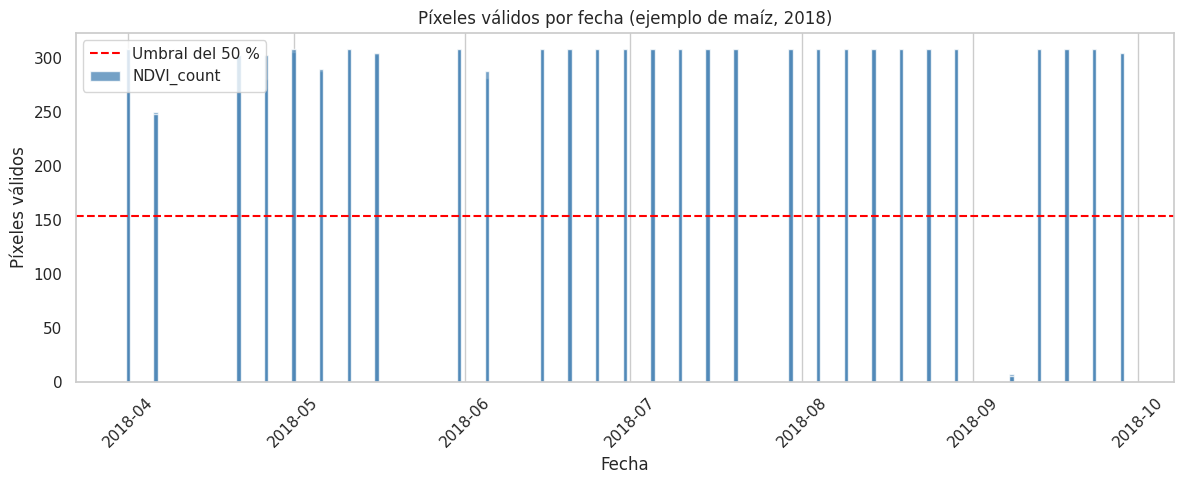

In [65]:
plt.figure(figsize=(12, 5))
plt.bar(df["date"], df["NDVI_count"], color="steelblue", alpha=0.75, label="NDVI_count")
plt.axhline(quality_threshold, color="red", linestyle="--", label="Umbral del 50 %")
plt.xlabel("Fecha")
plt.ylabel("Píxeles válidos")
plt.title("Píxeles válidos por fecha (ejemplo de maíz, 2018)")
plt.legend()
plt.grid(axis="y")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2.9 Evolución temporal del NDVI

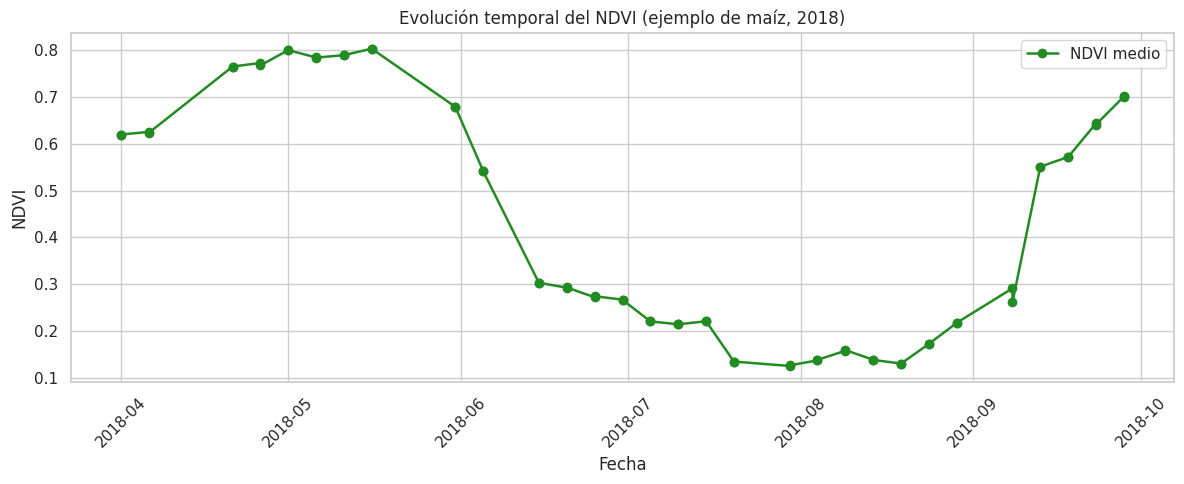

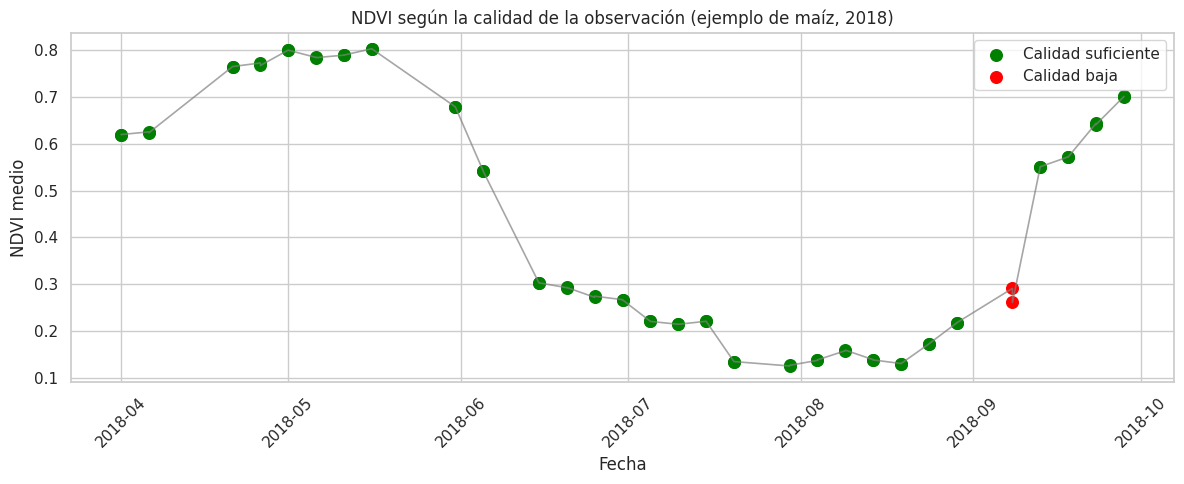

In [66]:
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["NDVI_mean"], marker="o", linewidth=1.8, color="forestgreen", label="NDVI medio")
plt.xlabel("Fecha")
plt.ylabel("NDVI")
plt.title("Evolución temporal del NDVI (ejemplo de maíz, 2018)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["NDVI_mean"], color="gray", linewidth=1.2, alpha=0.7)
plt.scatter(df.loc[valid_quality, "date"], df.loc[valid_quality, "NDVI_mean"],
            color="green", s=70, label="Calidad suficiente")
plt.scatter(df.loc[~valid_quality, "date"], df.loc[~valid_quality, "NDVI_mean"],
            color="red", s=70, label="Calidad baja")
plt.xlabel("Fecha")
plt.ylabel("NDVI medio")
plt.title("NDVI según la calidad de la observación (ejemplo de maíz, 2018)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2.10 Índices principales

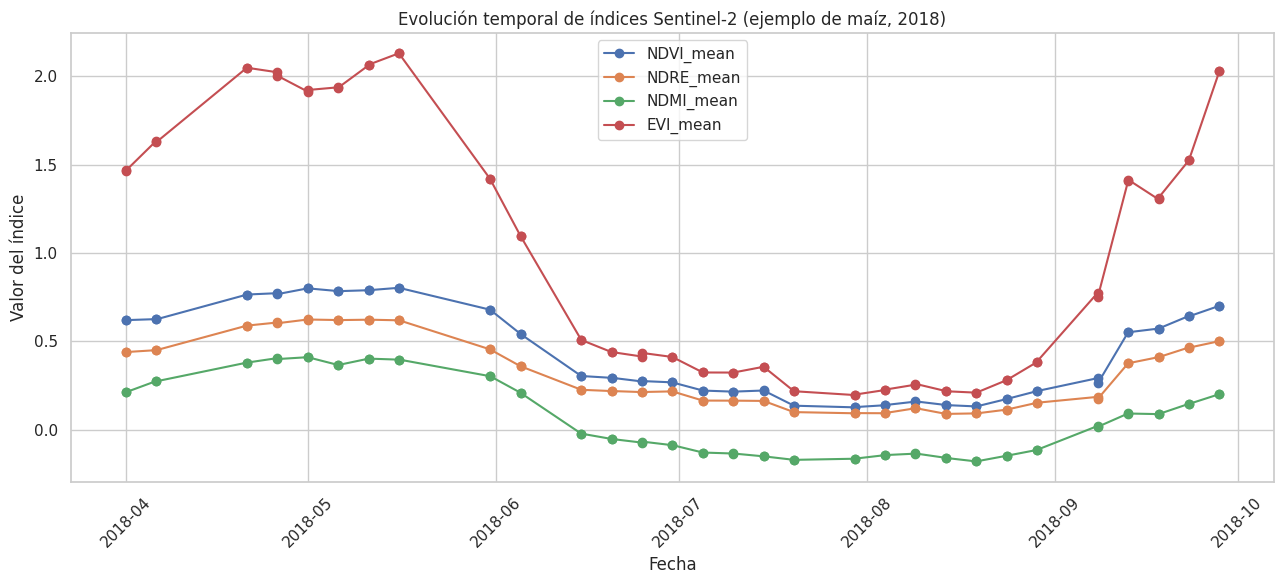

In [67]:
available_indices = [c for c in ["NDVI_mean", "NDRE_mean", "NDMI_mean", "EVI_mean"] if c in df.columns]

plt.figure(figsize=(13, 6))
for column in available_indices:
    plt.plot(df["date"], df[column], marker="o", linewidth=1.5, label=column)
plt.xlabel("Fecha")
plt.ylabel("Valor del índice")
plt.title("Evolución temporal de índices Sentinel-2 (ejemplo de maíz, 2018)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2.11 Guardar figura y estadísticas del ejemplo de 2018

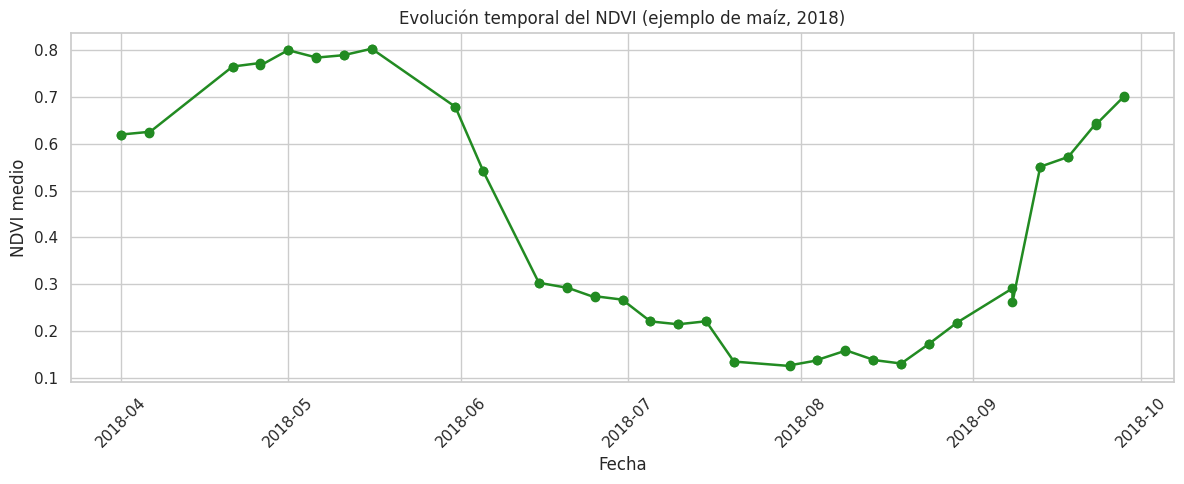

Figura guardada en: /content/drive/MyDrive/Sentinel2_Indices/resultados_exploracion/evolucion_ndvi.png
Estadísticas guardadas en: /content/drive/MyDrive/Sentinel2_Indices/resultados_exploracion/estadisticas_descriptivas_indices.csv


In [68]:
results_path = os.path.join(drive_path, "resultados_exploracion")
os.makedirs(results_path, exist_ok=True)

ndvi_figure_path = os.path.join(results_path, "evolucion_ndvi.png")

plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["NDVI_mean"], marker="o", linewidth=1.8, color="forestgreen")
plt.xlabel("Fecha")
plt.ylabel("NDVI medio")
plt.title("Evolución temporal del NDVI (ejemplo de maíz, 2018)")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(ndvi_figure_path, dpi=300, bbox_inches="tight")
plt.show()

statistics_path = os.path.join(results_path, "estadisticas_descriptivas_indices.csv")
descriptive_statistics.to_csv(statistics_path, encoding="utf-8-sig")

print("Figura guardada en:", ndvi_figure_path)
print("Estadísticas guardadas en:", statistics_path)

## 2.12 Conclusiones preliminares del ejemplo

- El CSV contiene observaciones procedentes de imágenes Sentinel-2, con dos filas
  por fecha (dos teselas).
- La serie presenta observaciones en fechas concretas, no una observación diaria.
- Los índices espectrales permiten analizar la evolución de la vegetación.
- `NDVI_count` es un indicador aproximado de calidad espacial.
- Las imágenes con pocos píxeles válidos deben estudiarse antes de incorporarlas
  al simulador.
- Sentinel-2 no proporciona directamente la humedad del suelo; hará falta
  información meteorológica y un modelo de balance hídrico.

## 2.13 Agrupación por fecha y filtro orientativo (ejemplo)

Algunas fechas tienen dos filas porque el polígono cae en dos teselas. Aquí se
agrupan por fecha calculando la **media simple** de las medias y se aplica de nuevo
el filtro orientativo sobre `NDVI_count`.

Esta agrupación **no pondera por píxeles** y **no interpola**: no se genera una serie
diaria ni valores estimados. La decisión sobre interpolación y sobre cómo resolver
varias imágenes por fecha se toma en la issue #4. La extracción de 2026 conserva una
sola imagen seleccionada por parcela y fecha y no interpola.

In [69]:
df = df.sort_values("date").reset_index(drop=True)

date_counts = df["date"].value_counts().sort_index()
number_of_unique_dates = df["date"].nunique()
dates_with_multiple_observations = int((date_counts > 1).sum())
rows_in_multiple_observation_dates = int(date_counts[date_counts > 1].sum())

ndvicount_max = df["NDVI_count"].max()
row_threshold = 0.5 * ndvicount_max
valid_rows_count = int((df["NDVI_count"] >= row_threshold).sum())

columns_for_grouping = [c for c in df.columns if c.endswith("_mean")]
if "NDVI_count" in df.columns:
    columns_for_grouping.append("NDVI_count")

daily_observed = df.groupby("date")[columns_for_grouping].mean().sort_index()

grouped_count_max = daily_observed["NDVI_count"].max()
grouped_threshold = 0.5 * grouped_count_max
valid_grouped_quality = daily_observed["NDVI_count"] >= grouped_threshold
daily_quality = daily_observed[valid_grouped_quality].copy()

summary = pd.DataFrame({
    "Métrica": [
        "Número de filas originales",
        "Número de columnas",
        "Número de fechas distintas",
        "Primera fecha",
        "Última fecha",
        "Fechas con múltiples observaciones",
        "Filas pertenecientes a fechas múltiples",
        "Valores nulos en NDVI_mean",
        "NDVI_count máximo por fila",
        "Umbral de calidad por fila",
        "Filas válidas antes de agrupar",
        "Filas después de agrupar",
        "NDVI_count máximo agrupado",
        "Umbral de calidad agrupado",
        "Fechas válidas después de agrupar",
    ],
    "Valor": [
        len(df),
        df.shape[1],
        number_of_unique_dates,
        df["date"].min(),
        df["date"].max(),
        dates_with_multiple_observations,
        rows_in_multiple_observation_dates,
        int(df["NDVI_mean"].isna().sum()),
        ndvicount_max,
        row_threshold,
        valid_rows_count,
        len(daily_observed),
        grouped_count_max,
        grouped_threshold,
        int(valid_grouped_quality.sum()),
    ],
})
display(summary)

summary_path = os.path.join(results_path, "resumen_exploracion.csv")
summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
print("Resumen guardado en:", summary_path)

print("\nComprobaciones:")
print("Filas originales:", len(df))
print("Fechas distintas:", df["date"].nunique())
print("Filas después de agrupar:", len(daily_observed))
print("Fechas duplicadas después de agrupar:", int(daily_observed.index.duplicated().sum()))
print("Fechas conservadas después del filtro:", len(daily_quality))

,Métrica,Valor
0,Número de filas originales,60
1,Número de columnas,123
2,Número de fechas distintas,30
3,Primera fecha,2018-04-01 00:00:00
4,Última fecha,2018-09-28 00:00:00
5,Fechas con múltiples observaciones,30
6,Filas pertenecientes a fechas múltiples,60
7,Valores nulos en NDVI_mean,0
8,NDVI_count máximo por fila,308
9,Umbral de calidad por fila,154.0


Resumen guardado en: /content/drive/MyDrive/Sentinel2_Indices/resultados_exploracion/resumen_exploracion.csv

Comprobaciones:
Filas originales: 60
Fechas distintas: 30
Filas después de agrupar: 30
Fechas duplicadas después de agrupar: 0
Fechas conservadas después del filtro: 29


## 2.14 Conclusiones de la agrupación (ejemplo)

- Se ha obtenido una única fila por fecha mediante la media simple de las medias.
- Se ha aplicado un filtro orientativo basado en `NDVI_count`.
- **No** se ha generado una serie diaria ni se ha interpolado ningún valor.
- La agrupación no pondera por número de píxeles de cada tesela; es una
  simplificación del ejemplo.
- El tratamiento definitivo de observaciones repetidas e interpolación se decide
  en la issue #4.